## Step 1

load Data and import datetime and pandas

In [92]:
import pandas as pd
from datetime import datetime

df = pd.read_csv("project_dataset.csv",sep=";")
df_test = None 

filtering by service

In [93]:
df = df[(df["Service"].notna())]

filtering by departure station

In [94]:
df = df[(df["Gare de départ"]).notna()]

filtering by arrival station

In [95]:
df = df[(df["Gare d\'arrivée"]).notna()]

filtering by average travel time

In [96]:
df = df[(df["Durée moyenne du trajet"]).notna()]

def clean_string_to_float(elem): 

    # the objective of the funtion it's to convert "212,1 min" in "212.1"

    elem = str(elem) # force elem input in str
    elem = elem.replace(",",".") #replace , by .
    elem = elem.replace("min","") # repalce min by nothinh
    elem = elem.strip() #remove space in more
    return float(elem)

df["Durée moyenne du trajet"] = df["Durée moyenne du trajet"].apply(clean_string_to_float)
df = df[(df["Durée moyenne du trajet"] <= 500 )]

filtering by date

In [97]:
df = df[(df["Date"]).notna()]

def parse_date_flexible(val):

    val = str(val).strip()  # Convert to string and remove leading/trailing spaces
    val = val.replace("/", "-")
    val = val.replace(" ", "-")  # Normalize separators to '-'
    
    parts = val.split("-") #swap the position of the elements if date format is 08-2018
    if len(parts[0]) == 2:
        val = parts[1]+"-"+parts[0]
    
    return val


 
df["Date"] = df["Date"].apply(parse_date_flexible)

filtering by number of planned circulations

In [98]:
df = df[(df["Nombre de circulations prévues"]).notna()]

df["Nombre de circulations prévues"] = df["Nombre de circulations prévues"].apply(clean_string_to_float).astype("float").astype("int")
# I change number of planned content circulations content by int

filtering by number of canceled trains

In [99]:
df["Nombre de trains annulés"] = df["Nombre de trains annulés"].fillna(0)
#I replace nan value by 0 that mean no trains were cancel
df["Nombre de trains annulés"] = df["Nombre de trains annulés"].apply(clean_string_to_float).astype("float").astype("int")
df = df[(df["Nombre de trains annulés"] < 190)]

filtering by cancellation comment

In [100]:
df["Commentaire annulations"] = df["Commentaire annulations"].fillna("NC")
#I replace nan value by NC that mean trains haven't any comments
df["Commentaire annulations"] = df["Commentaire annulations"].replace("Non communiqué","NC")
df["Commentaire annulations"] = df["Commentaire annulations"].replace("-","NC")

filtering by number of trains delayed on departure

In [101]:
df["Nombre de trains en retard au départ"] = df["Nombre de trains en retard au départ"].fillna(0)
#I replace nan value by 0 that mean train aren't delay
df["Nombre de trains en retard au départ"] = df["Nombre de trains en retard au départ"].apply(clean_string_to_float).astype("float").astype("int")
df = df[(df["Nombre de trains en retard au départ"] < 400)]

filtering by average delay of trains delayed at departure

In [102]:
df["Retard moyen des trains en retard au départ"] = df["Retard moyen des trains en retard au départ"].fillna(0.0)
df["Retard moyen des trains en retard au départ"] = df["Retard moyen des trains en retard au départ"].apply(clean_string_to_float).astype("float")
df = df[(df["Retard moyen des trains en retard au départ"] < 60)]

filtering by average delay of all departing trains

In [103]:
df["Retard moyen de tous les trains au départ"] = df["Retard moyen de tous les trains au départ"].fillna(0.0)
df["Retard moyen de tous les trains au départ"] = df["Retard moyen de tous les trains au départ"].apply(clean_string_to_float).astype("float")
df = df[(df["Retard moyen de tous les trains au départ"] < 10) & (df["Retard moyen de tous les trains au départ"] > 0)]

filtering by comment on departure delays

In [104]:
df["Commentaire retards au départ"] = df["Commentaire retards au départ"].fillna("NC")
#I replace nan value by NC that mean trains haven't any comments
df["Commentaire retards au départ"] = df["Commentaire retards au départ"].replace("Non communiqué","NC")
df["Commentaire retards au départ"] = df["Commentaire retards au départ"].replace("-","NC")

filtering by number of trains arriving late

In [105]:
df["Nombre de trains en retard à l'arrivée"] = df["Nombre de trains en retard à l'arrivée"].fillna(0)
#I replace nan value by 0 that mean train aren't delay
df["Nombre de trains en retard à l'arrivée"] = df["Nombre de trains en retard à l'arrivée"].apply(clean_string_to_float).astype("float").astype("int")
df = df[(df["Nombre de trains en retard à l'arrivée"] < 125)]

filtering by average delay of trains arriving late

In [106]:
#Retard moyen des trains en retard à l'arrivée
df["Retard moyen des trains en retard à l'arrivée"] = df["Retard moyen des trains en retard à l'arrivée"].fillna(0.0)
df["Retard moyen des trains en retard à l'arrivée"] = df["Retard moyen des trains en retard à l'arrivée"].apply(clean_string_to_float).astype("float")
df = df[(df["Retard moyen des trains en retard à l'arrivée"] < 125) & (df["Retard moyen des trains en retard à l'arrivée"] > -1)]

filtering by average delay of all trains arriving

In [107]:
#Retard moyen de tous les trains à l'arrivée
df["Retard moyen de tous les trains à l'arrivée"] = df["Retard moyen de tous les trains à l'arrivée"].fillna(0.0)
df["Retard moyen de tous les trains à l'arrivée"] = df["Retard moyen de tous les trains à l'arrivée"].apply(clean_string_to_float).astype("float")
df = df[(df["Retard moyen de tous les trains à l'arrivée"] < 15) & (df["Retard moyen de tous les trains à l'arrivée"] > 0)]

filtering by comments on delays on arrival

In [108]:
#Commentaire retards à l'arrivée
df["Commentaire retards à l'arrivée"] = df["Commentaire retards à l'arrivée"].fillna("NC")
#I replace nan value by NC that mean trains haven't any comments
df["Commentaire retards à l'arrivée"] = df["Commentaire retards à l'arrivée"].replace("Non communiqué","NC")
df["Commentaire retards à l'arrivée"] = df["Commentaire retards à l'arrivée"].replace("-","NC")

filtering by number of trains delayed > 15 min

In [109]:
df["Nombre trains en retard > 15min"] = df["Nombre trains en retard > 15min"].fillna(0)
#I replace nan value by 0 that mean train aren't delay
df["Nombre trains en retard > 15min"] = df["Nombre trains en retard > 15min"].apply(clean_string_to_float).astype("float").astype("int")
df = df[df["Nombre trains en retard > 15min"] >= 0]

filtering by average delay of trains delayed > 15 min

In [110]:
df["Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"] = df["Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"].fillna(0.0)
df["Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"] = df["Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"].apply(clean_string_to_float).astype("float")
df = df[(df["Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"] > -50) & (df["Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"] < 125)]

filtering by number of trains delayed > 30 min

In [111]:
df["Nombre trains en retard > 30min"] = df["Nombre trains en retard > 30min"].fillna(0)
#I replace nan value by 0 that mean train aren't delay
df["Nombre trains en retard > 30min"] = df["Nombre trains en retard > 30min"].apply(clean_string_to_float).astype("float").astype("int")
df = df[(df["Nombre trains en retard > 30min"] >= 0) & (df["Nombre trains en retard > 30min"] < 80) ]

filtering by number of trains delayed > 60 min

In [112]:
df["Nombre trains en retard > 60min"] = df["Nombre trains en retard > 60min"].fillna(0)
#I replace nan value by 0 that mean train aren't delay
df["Nombre trains en retard > 60min"] = df["Nombre trains en retard > 60min"].apply(clean_string_to_float).astype("float").astype("int")
df = df[(df["Nombre trains en retard > 60min"] >= 0) & (df["Nombre trains en retard > 60min"] < 50)]

filtering by pourcentage of trains delay

In [113]:
CAUSE_COLS = [
        "Prct retard pour causes externes",
        "Prct retard pour cause infrastructure",
        "Prct retard pour cause gestion trafic",
        "Prct retard pour cause matériel roulant",
        "Prct retard pour cause gestion en gare et réutilisation de matériel",
        "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
]
    
for col in CAUSE_COLS:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")#non-convertible values are converted to float and become NaN
    df[col] = df[col].fillna(0.0)
    #NaN means that this cause does not apply and sets it to 0, but we could also set df = df[(df[“column_name”]).notna()], but I prefer to keep 0 to have a value rather than nothing.


df = df[(df["Prct retard pour causes externes"] < 90)]
df = df[(df["Prct retard pour cause infrastructure"] < 90)]
df = df[(df["Prct retard pour cause gestion trafic"] < 70)]
df = df[(df["Prct retard pour cause matériel roulant"] < 70)]
df = df[(df["Prct retard pour cause gestion en gare et réutilisation de matériel"] < 60)]
df = df[(df["Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"] < 50)]

save cleaned df in cleaned_dataset.csv

In [114]:
df.to_csv("cleaned_dataset.csv", index= False)
if df_test:
    df_test.to_csv("test_dataset.csv",index=False)
print(len(df["Retard moyen des trains en retard à l'arrivée"].values))

9280


## Step 2

import matplotlib,seaborn and clean df

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns

cleaned_df = pd.read_csv("cleaned_dataset.csv")

Graph showing the total train delay time per year

In [116]:
data = {}

min_year = 2022
max_year = 2025

for index,row in cleaned_df.iterrows() : #loop for each line in the df
    city = row["Gare d'arrivée"]
    date_year = datetime.strptime(row["Date"],"%Y-%m").year #we retrieve the year from the date on the line
    delay = row["Retard moyen de tous les trains à l'arrivée"]
    if min_year <= date_year <= max_year: 
        if city not in data.keys() :
            data[city] = {
                date_year : delay
            }
            #If there is no data on the station, we create it.
        else :
            if date_year in data[city].keys():
                data[city][date_year] += delay
                #if the city already exists in the data and the year too, we add the delay
            else :
                data[city][date_year] = delay
                #if the city exists but not the year, then we create the year

data = dict(sorted(data.items()))

df = pd.DataFrame(data)
df = df.sort_index(ascending=True)
df = df.reset_index().melt(id_vars='index', var_name='column', value_name='value')
#reshaping the dataframe to a longer format

plt.figure(figsize=(20,20))
sns.barplot(x="value", y="column" , data=df, hue="index", orient='h')
plt.title('Total Min of delay per year')
plt.xlabel('Total Delay Min')
plt.ylabel('Station')
plt.yticks(list(data.keys()),fontsize=2)
plt.savefig('graph1.png', dpi=300, bbox_inches='tight', transparent=False)
plt.close()


Graph pourcentage of trains delay

In [ ]:
df = cleaned_df

CAUSE_COLS = [
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
]

valeurs = df[CAUSE_COLS].mean()

plt.figure(figsize=(9, 9))
plt.pie(
    valeurs,
    labels=[label.replace('Prct retard pour ', '') for label in CAUSE_COLS],
    autopct='%1.1f%%',
    startangle=45,
    colors=plt.cm.tab10.colors
)#function that creates a circle with the different values given to make a graph, to separate the different causes
plt.title('Répartition des causes de retard')
plt.axis('equal')
plt.savefig('graph2.png', dpi=300, bbox_inches='tight', transparent=False)
plt.close()

Graph showing the accumulated delay along the path

In [118]:
data = {"station":[],"departure_delay":[],"arrived_delay":[],"accumulated_delay":[]}

min_year = datetime.strptime("2025-01","%Y-%m")
max_year = datetime.strptime("2025-04","%Y-%m")


for index,row in cleaned_df.iterrows():
    date_row = datetime.strptime(row["Date"],"%Y-%m")
    if min_year <= date_row <= max_year : 
        data["station"].append(row["Gare de départ"]+"-->"+row["Gare d'arrivée"])
        data["departure_delay"].append(row["Retard moyen de tous les trains au départ"])
        data["arrived_delay"].append(row["Retard moyen de tous les trains à l'arrivée"])
        data["accumulated_delay"].append(row["Retard moyen de tous les trains à l'arrivée"]-row["Retard moyen de tous les trains au départ"])

df = pd.DataFrame(data)
df.set_index('station', inplace=True)
ax = df.plot(kind='bar', figsize=(len(df.index)/5, 10), width=0.8)
ax.set_title('Showing the accumulated delay along the path')
ax.set_ylabel('Delay min')
plt.xticks(rotation=45,fontsize=2,ha="right")
plt.legend(title='Groups')
plt.savefig('graph3.png', dpi=300, bbox_inches='tight', transparent=False)
plt.close()

Heatmap to see the correlation between columns

In [119]:
data = cleaned_df
data["Date"] = pd.to_datetime(data["Date"],format="%Y-%m")
corr_cleaned_df = data.corr(numeric_only=True)

plt.figure(figsize=(15,15))
sns.heatmap(corr_cleaned_df,annot=True,cmap="coolwarm")
plt.savefig('graph4.png', dpi=300, bbox_inches='tight', transparent=False)
plt.close()

Boxplot to see outliers

/tmp/ipykernel_71133/2729911588.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,ax = plt.subplots(figsize=(8,3))


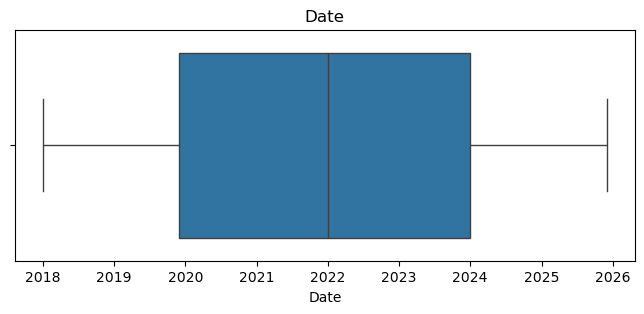

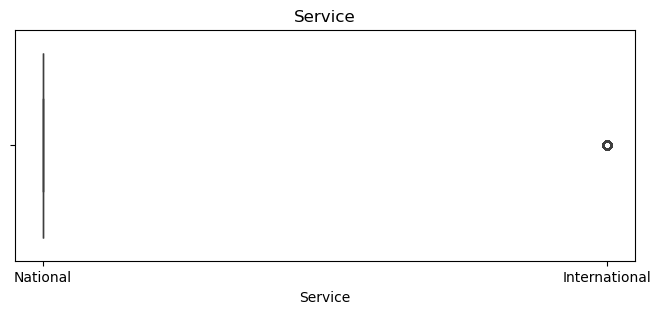

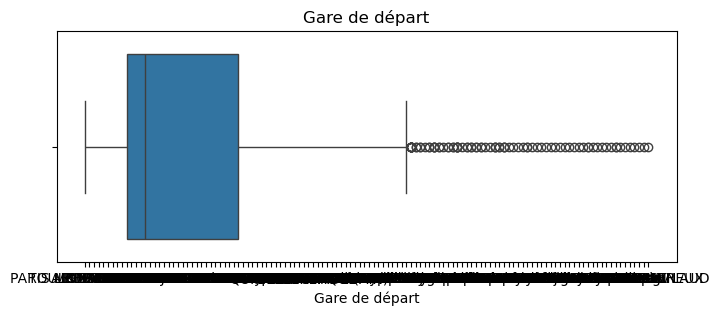

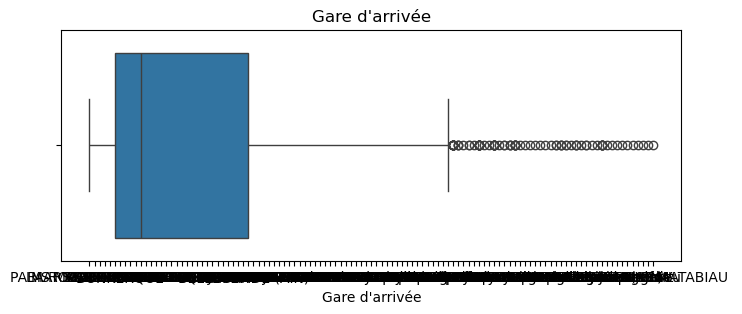

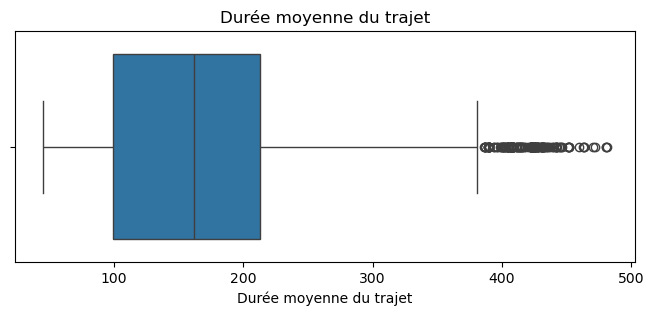

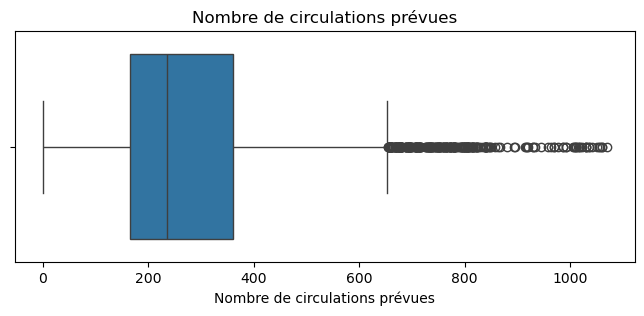

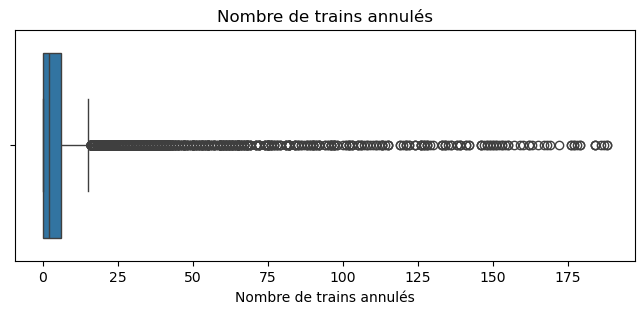

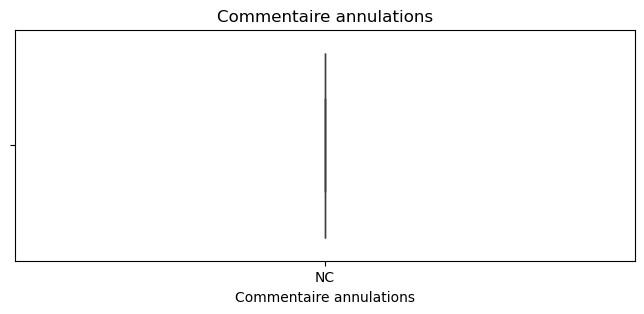

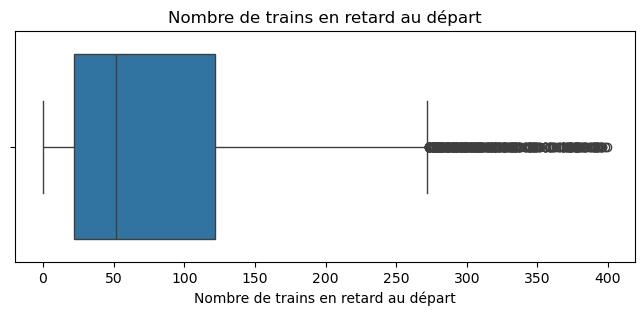

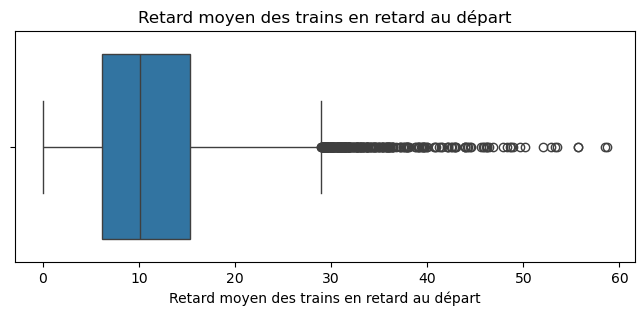

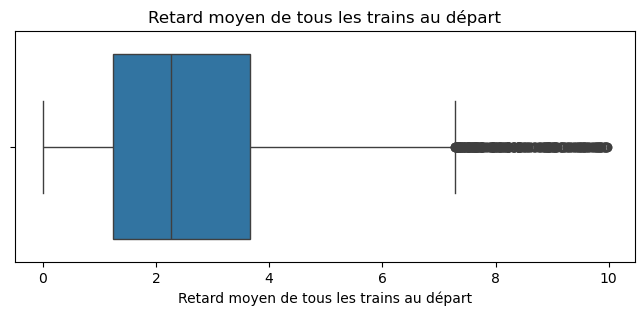

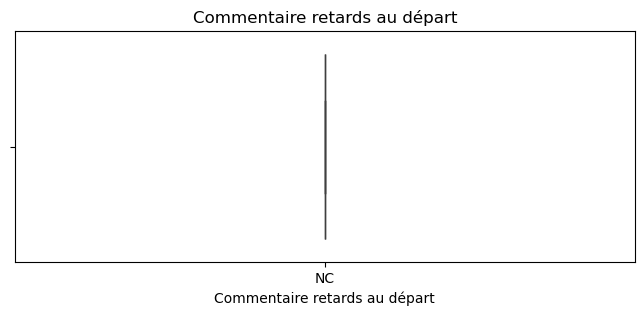

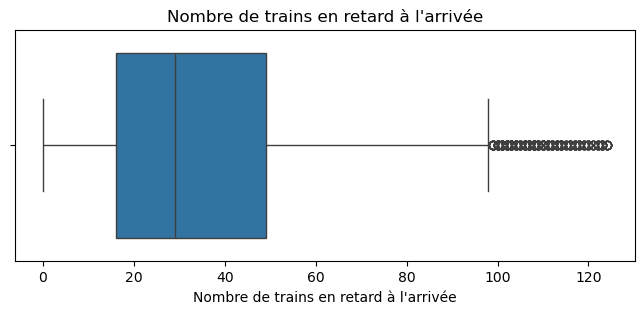

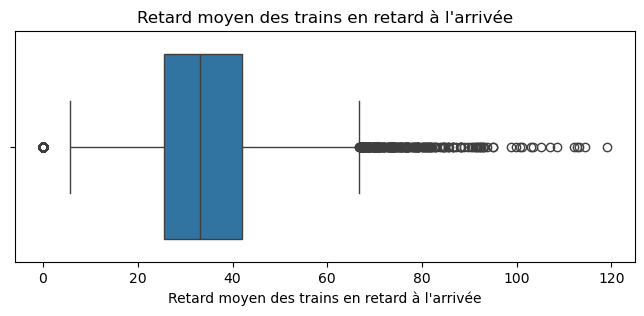

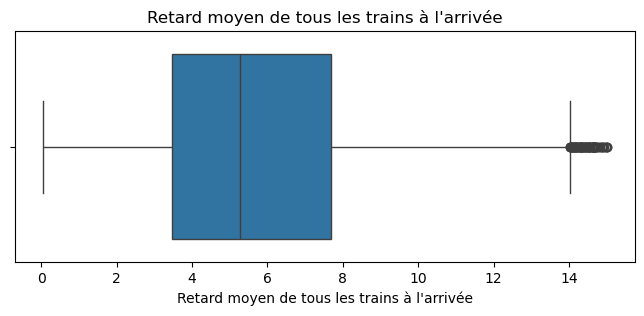

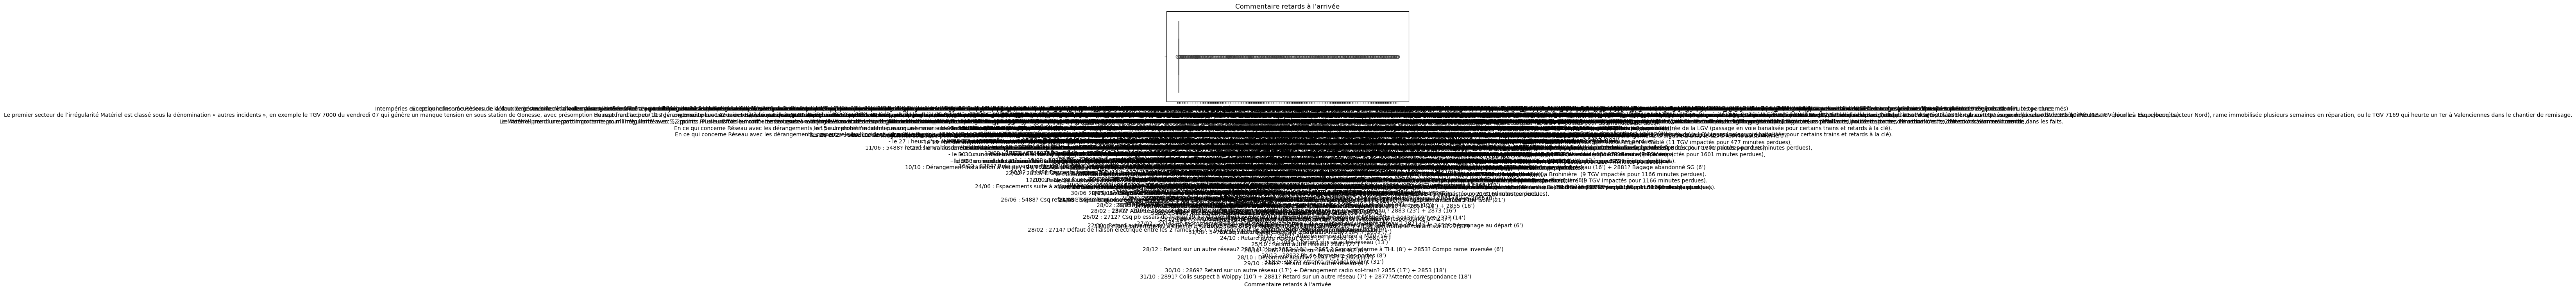

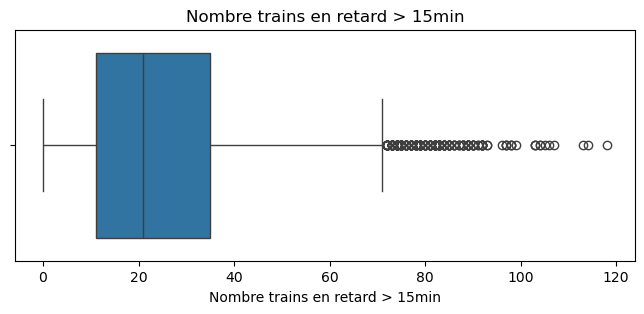

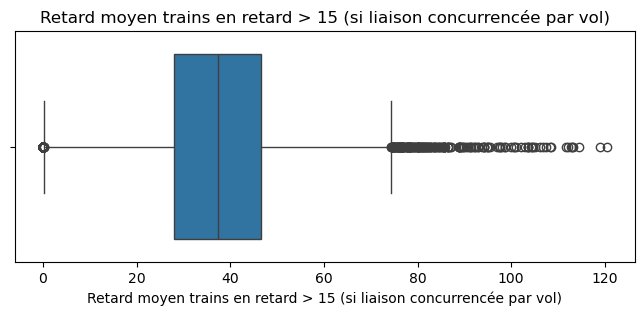

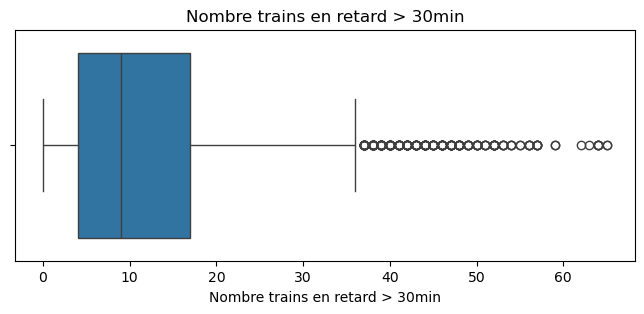

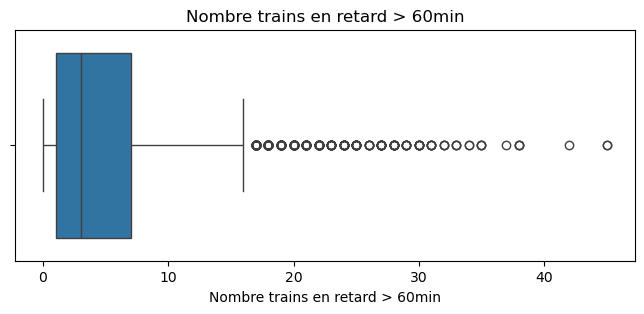

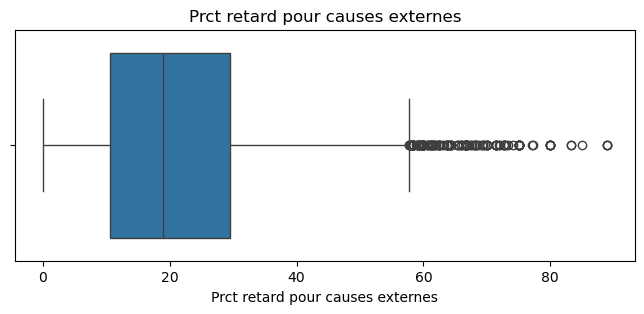

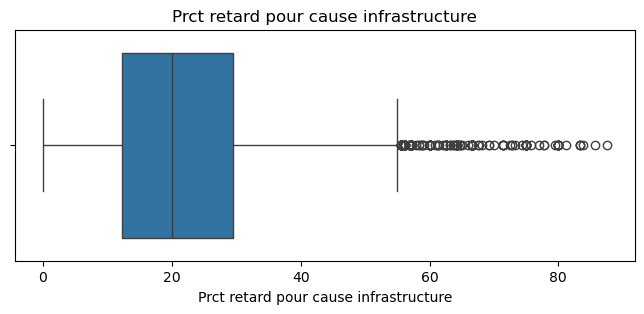

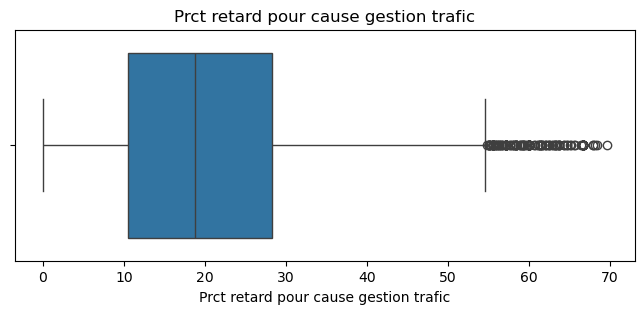

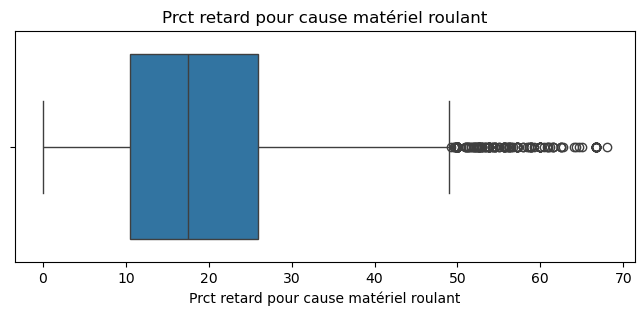

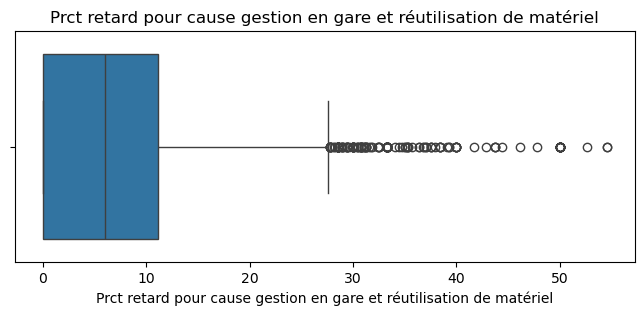

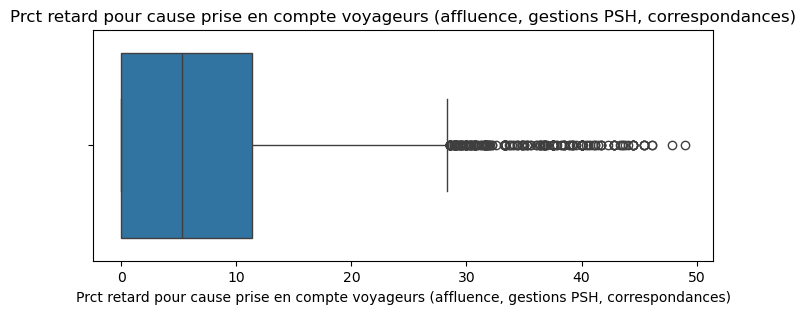

In [120]:

for column in data.columns:
    if data[column].dtype != "str":
        fig,ax = plt.subplots(figsize=(8,3))
        sns.boxplot(x=data[column], ax=ax)
        plt.title(column)
        plt.show 

Scatter plot between each column and average delay of all trains on arrival

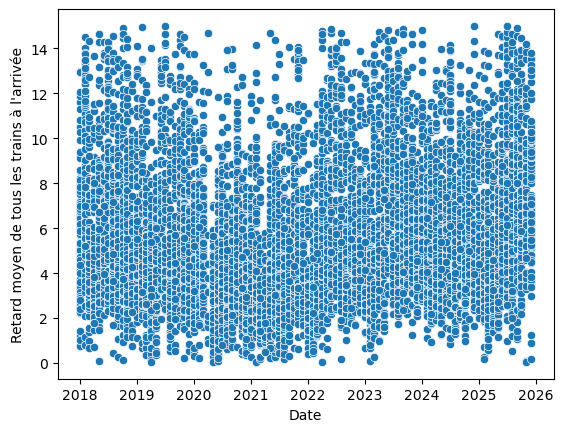

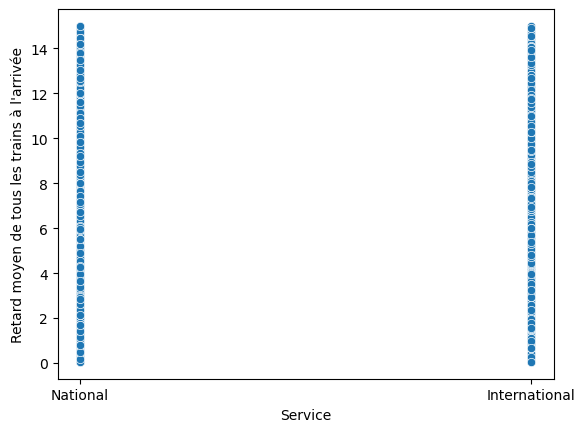

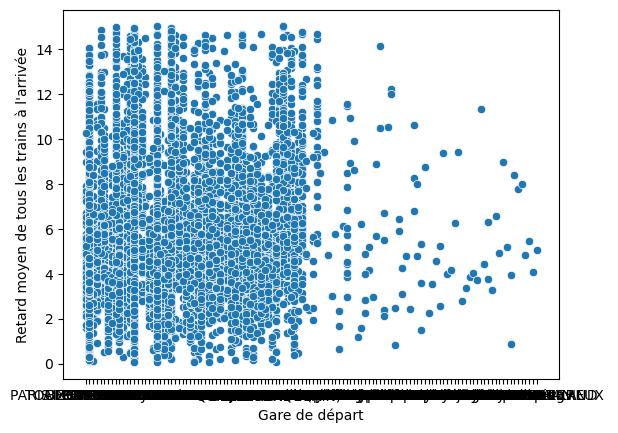

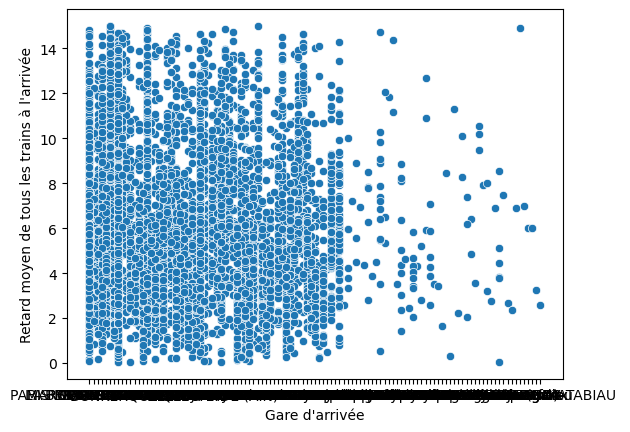

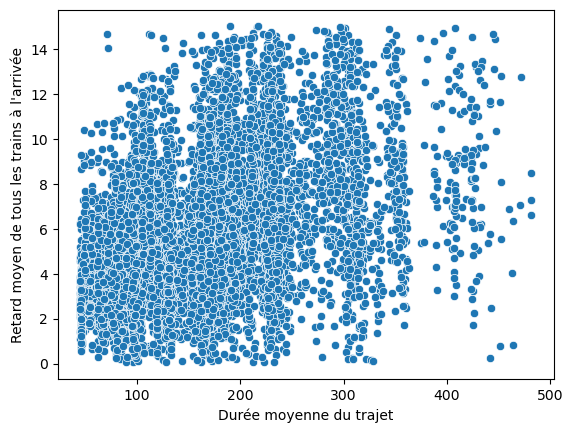

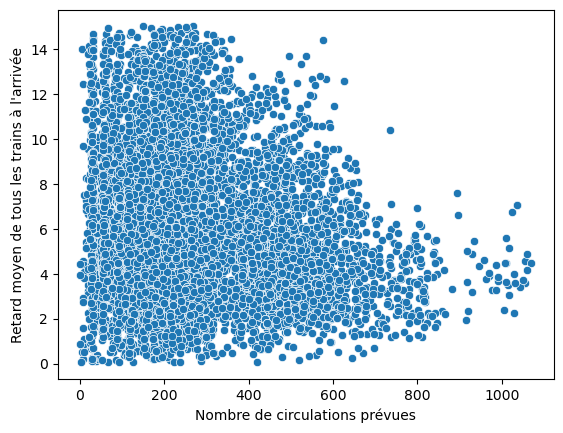

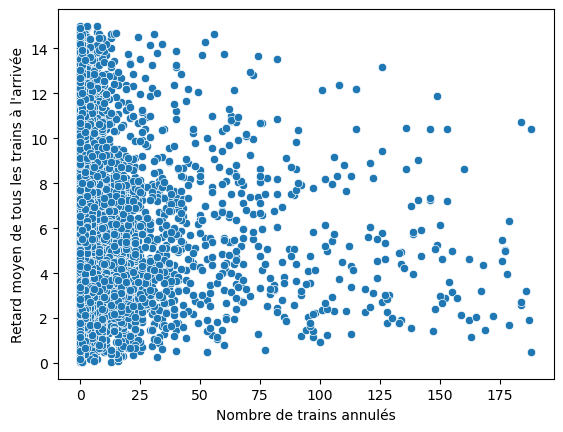

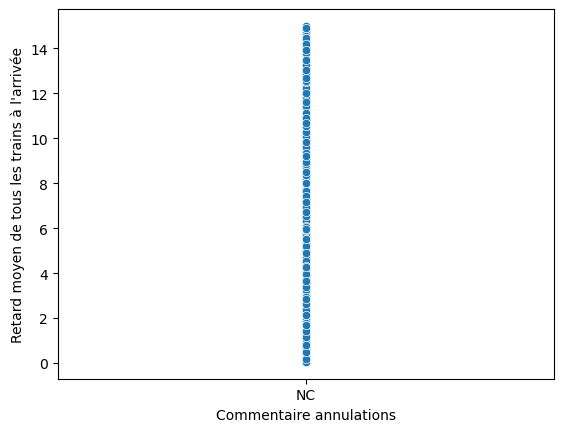

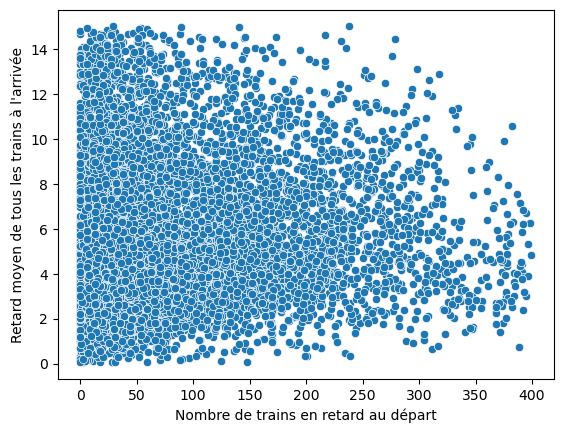

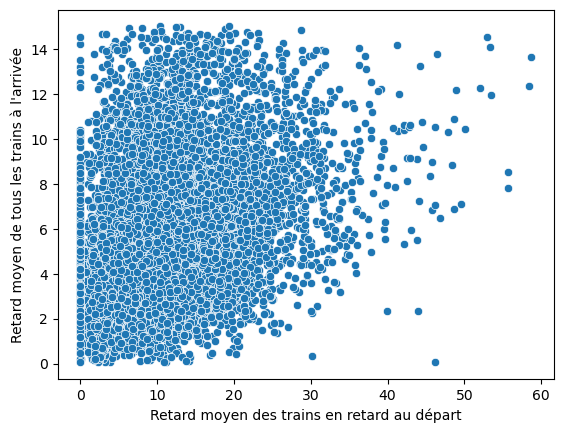

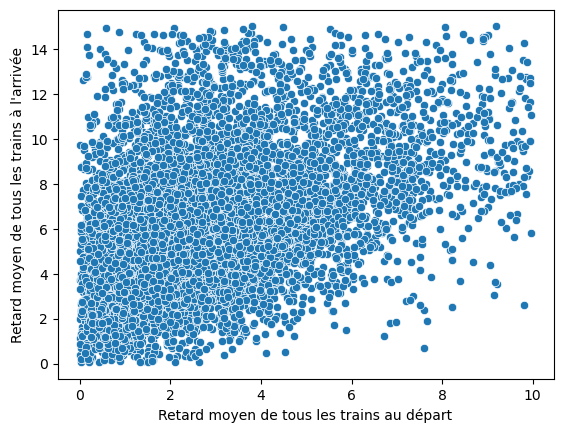

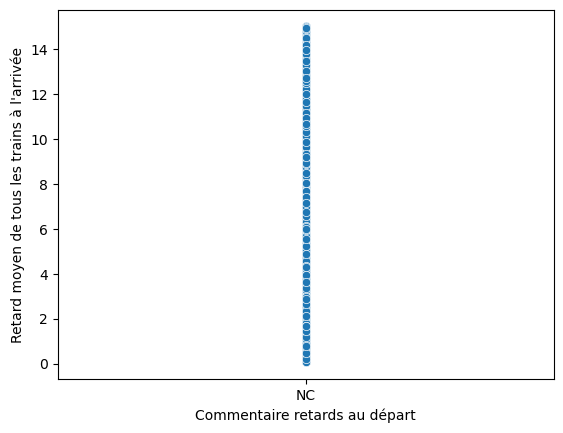

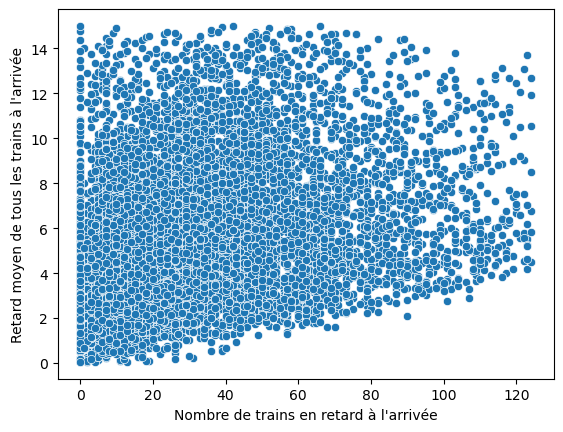

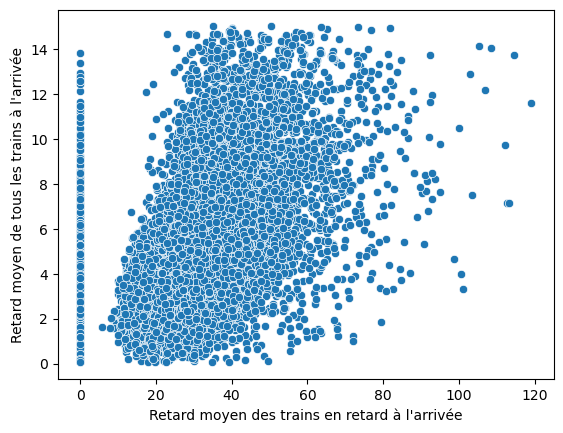

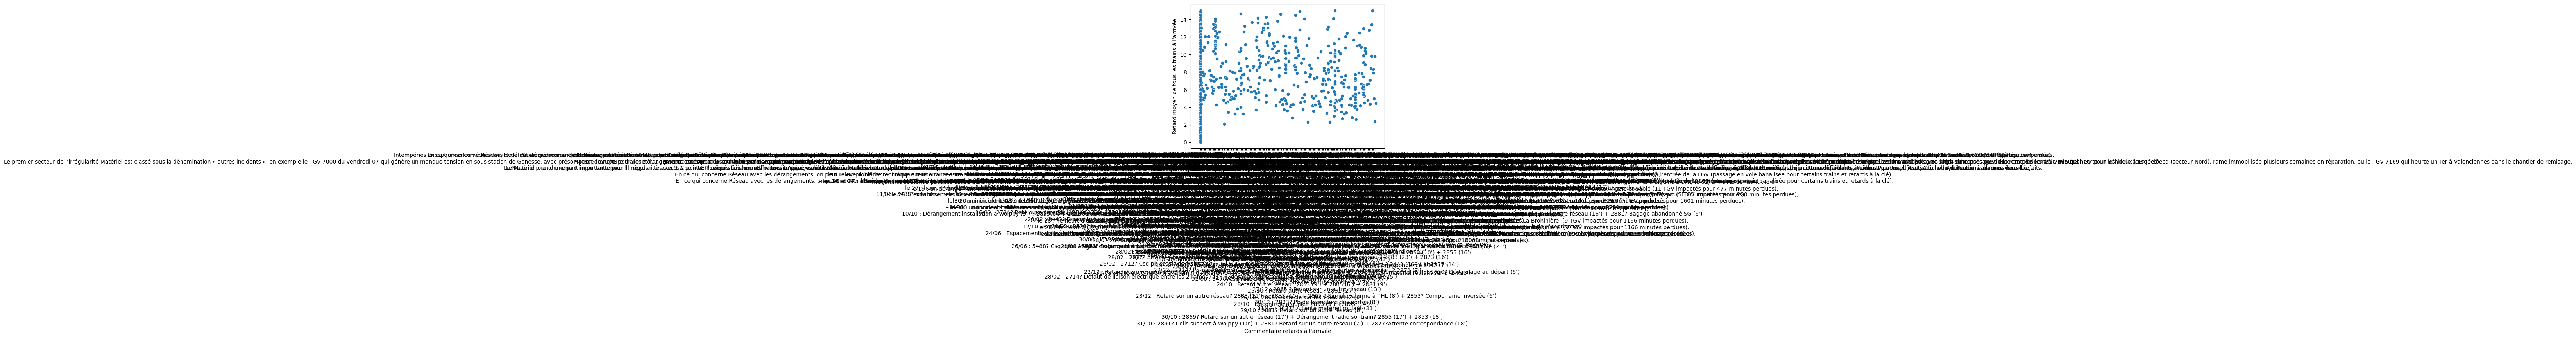

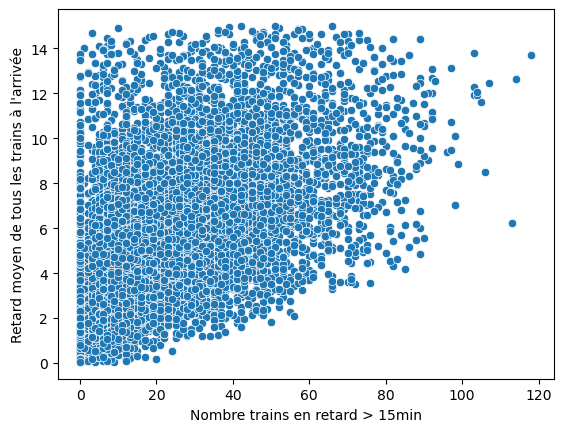

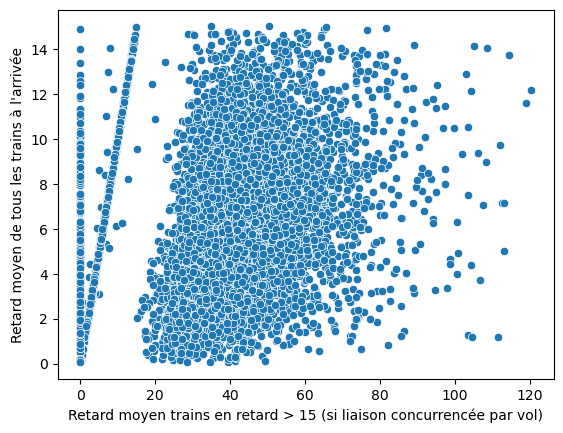

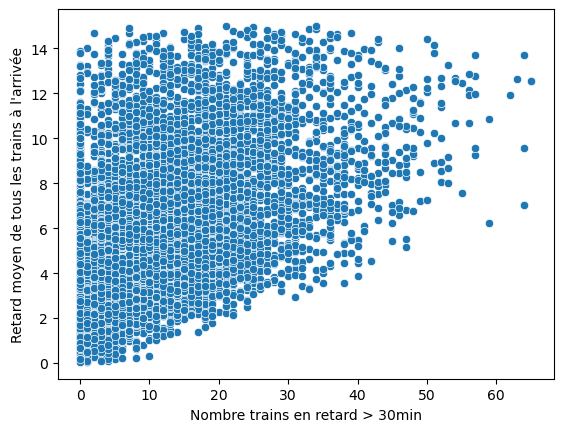

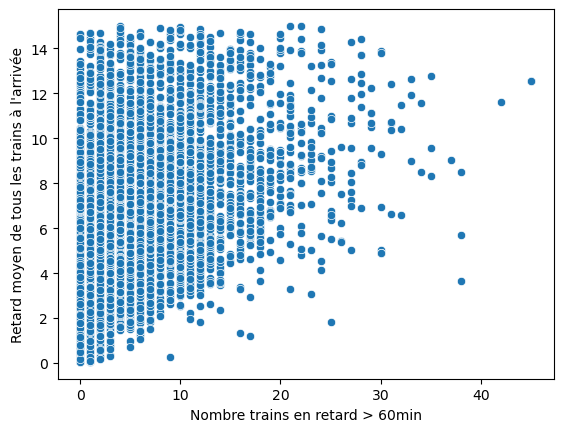

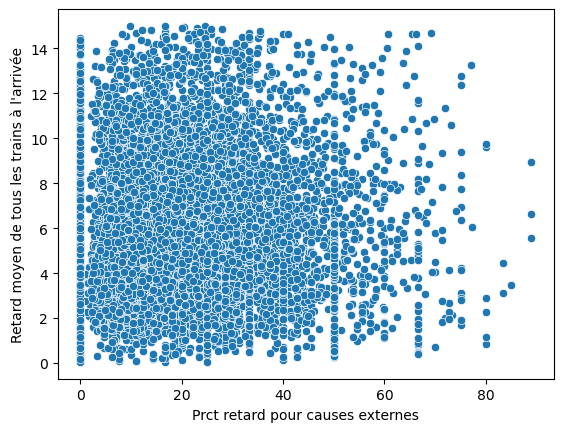

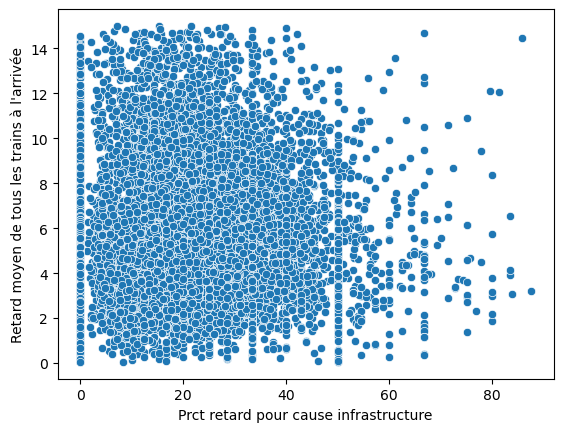

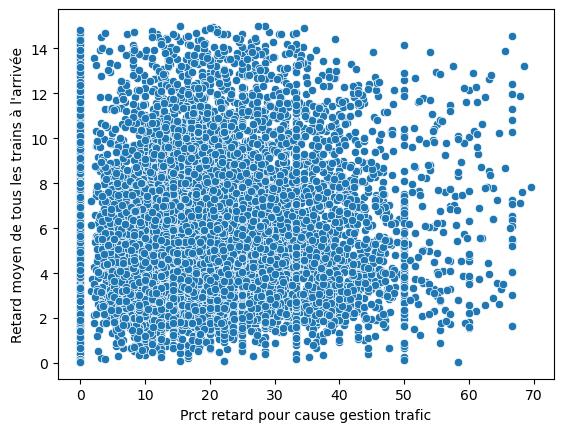

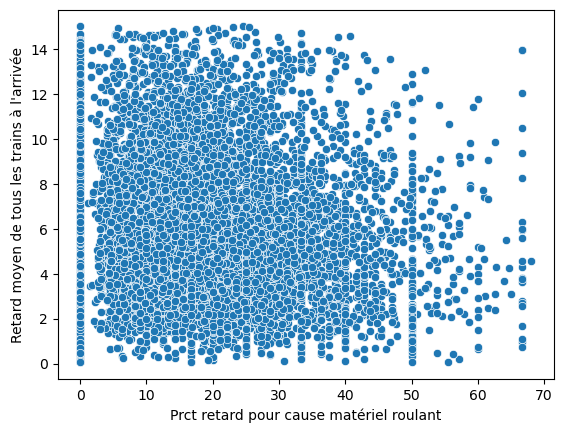

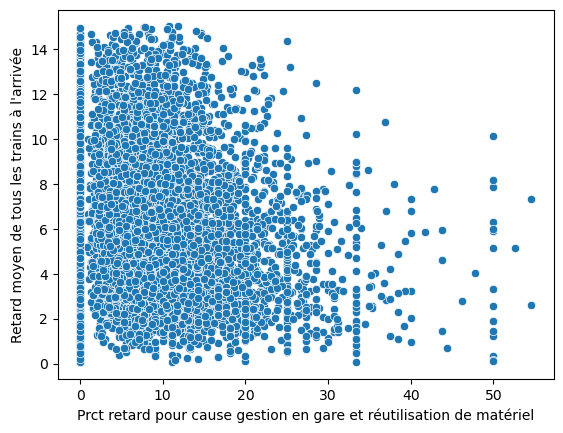

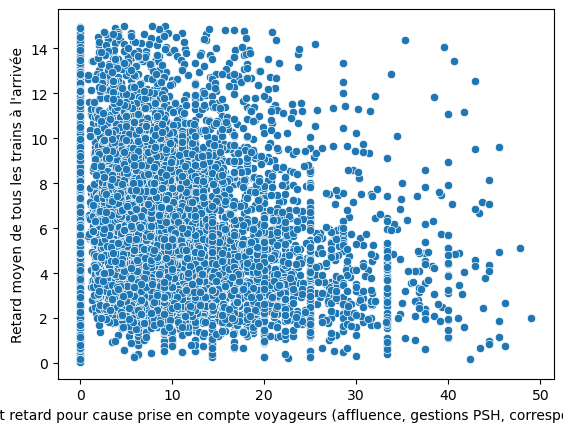

In [121]:

X = data.drop("Retard moyen de tous les trains à l'arrivée",axis=1)

for col in X.columns:
    sns.scatterplot(x=X[col], y=data["Retard moyen de tous les trains à l'arrivée"])
    plt.show()